In [1]:
import tifffile
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
visual_root=Path("/projects/vasishtgroup/yutao4/leoedge/data/band_test/visual/")
analytic_root=Path("/projects/vasishtgroup/yutao4/leoedge/data/band_test/analytic/")

In [3]:
analytic_band_value=[[],[],[]]
visual_band_value=[[],[],[]]
for visual_file in visual_root.glob("*Visual_clip.tif"):
    analytic_file=analytic_root/(visual_file.name.replace("Visual","AnalyticMS"))
    visual_image=tifffile.imread(visual_file)
    analytic_image=tifffile.imread(analytic_file)
    for i in range(3):
        total_pixels=visual_image.shape[0]*visual_image.shape[1]
        random_index=np.random.randint(0,total_pixels,10000)
        analytic_band_value[i].extend(analytic_image[:,:,2-i].flatten()[random_index])
        visual_band_value[i].extend(visual_image[:,:,i].flatten()[random_index])

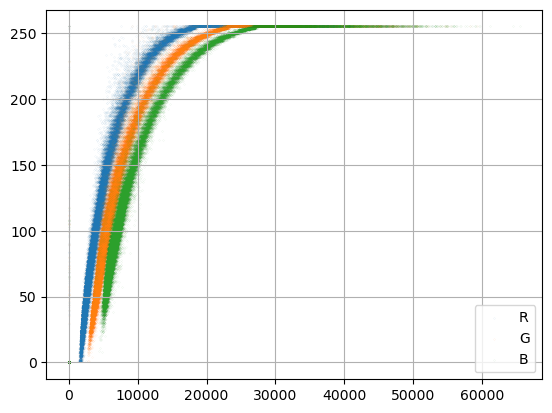

In [4]:
plt.scatter(analytic_band_value[0],visual_band_value[0],s=.001,label="R")
plt.scatter(analytic_band_value[1],visual_band_value[1],s=.001,label="G")
plt.scatter(analytic_band_value[2],visual_band_value[2],s=.001,label="B")
plt.legend()
plt.grid()

/tmp/ipykernel_44361/1543645143.py:5: RuntimeWarning: invalid value encountered in log
  y =  a*np.log(x+b)+c


[ 128.28011414  267.30789712 -965.33834778]
[ 1.29298516e+02  7.34768307e-06 -1.01149158e+03]


/home/yutao4/.conda/envs/torch/lib/python3.10/site-packages/scipy/optimize/_minpack_py.py:906: OptimizeWarning: Covariance of the parameters could not be estimated
  warnings.warn('Covariance of the parameters could not be estimated',


[ 1.53832236e+02  1.20716774e-05 -1.26190869e+03]


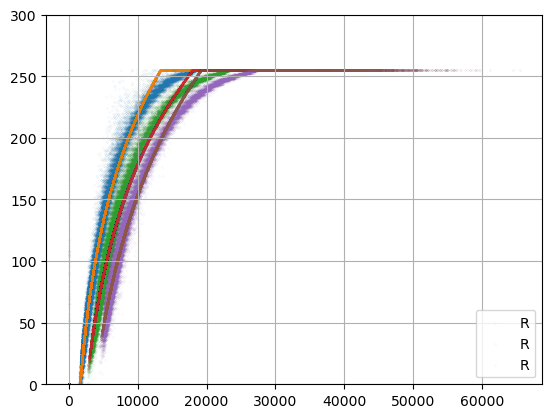

In [5]:
from scipy.optimize import curve_fit
popts=[]
for i in range(3):
    def transform(x, a, b, c):
        y =  a*np.log(x+b)+c
        y = np.clip(y,0,255)
        return y
        
    popt,pcov=curve_fit(transform,analytic_band_value[i],visual_band_value[i], maxfev=100000)
    popts.append(popt)
    print(popt)
    plt.scatter(analytic_band_value[i],visual_band_value[i],s=.001)
    y = transform(analytic_band_value[i],*popt)
    y = np.clip(y,0,255)
    plt.scatter(analytic_band_value[i],y,s=.001,label="R")
    plt.legend()
    #let's zoom in between 200 and 255 y
    plt.ylim(0,300)
    plt.grid()
import pickle
with open("../results/model/transform.pkl","wb+") as f:
    pickle.dump(popts,f)

In [6]:
import tifffile
sample_image=tifffile.imread("../data/band_test/analytic/20230218_030554_61_24a3_3B_AnalyticMS_clip.tif")

In [7]:
red_function=lambda img:transform(img[:,:,2],*popts[0])
green_function=lambda img:transform(img[:,:,1],*popts[1])
blue_function=lambda img:transform(img[:,:,0],*popts[2])
transformed_image=np.stack([red_function(sample_image),green_function(sample_image),blue_function(sample_image)],axis=2)

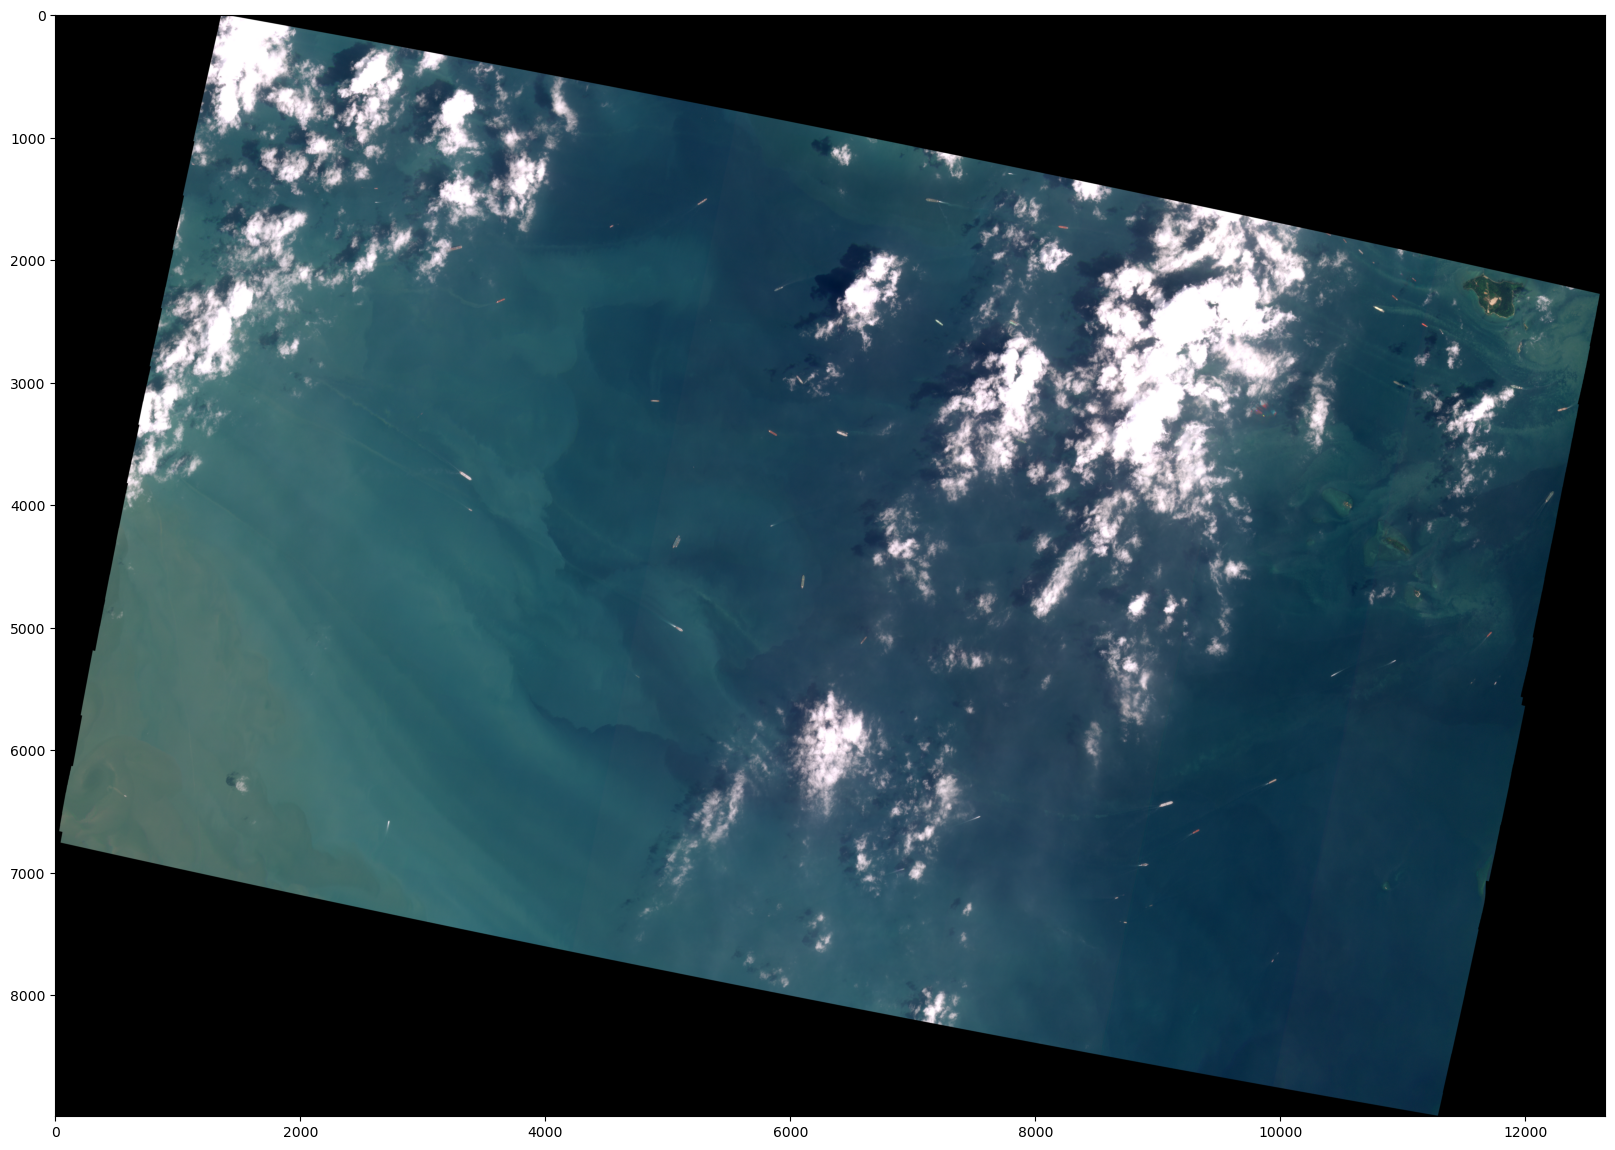

In [8]:
plt.figure(figsize=(20,20))
plt.imshow(transformed_image.astype(np.uint8))

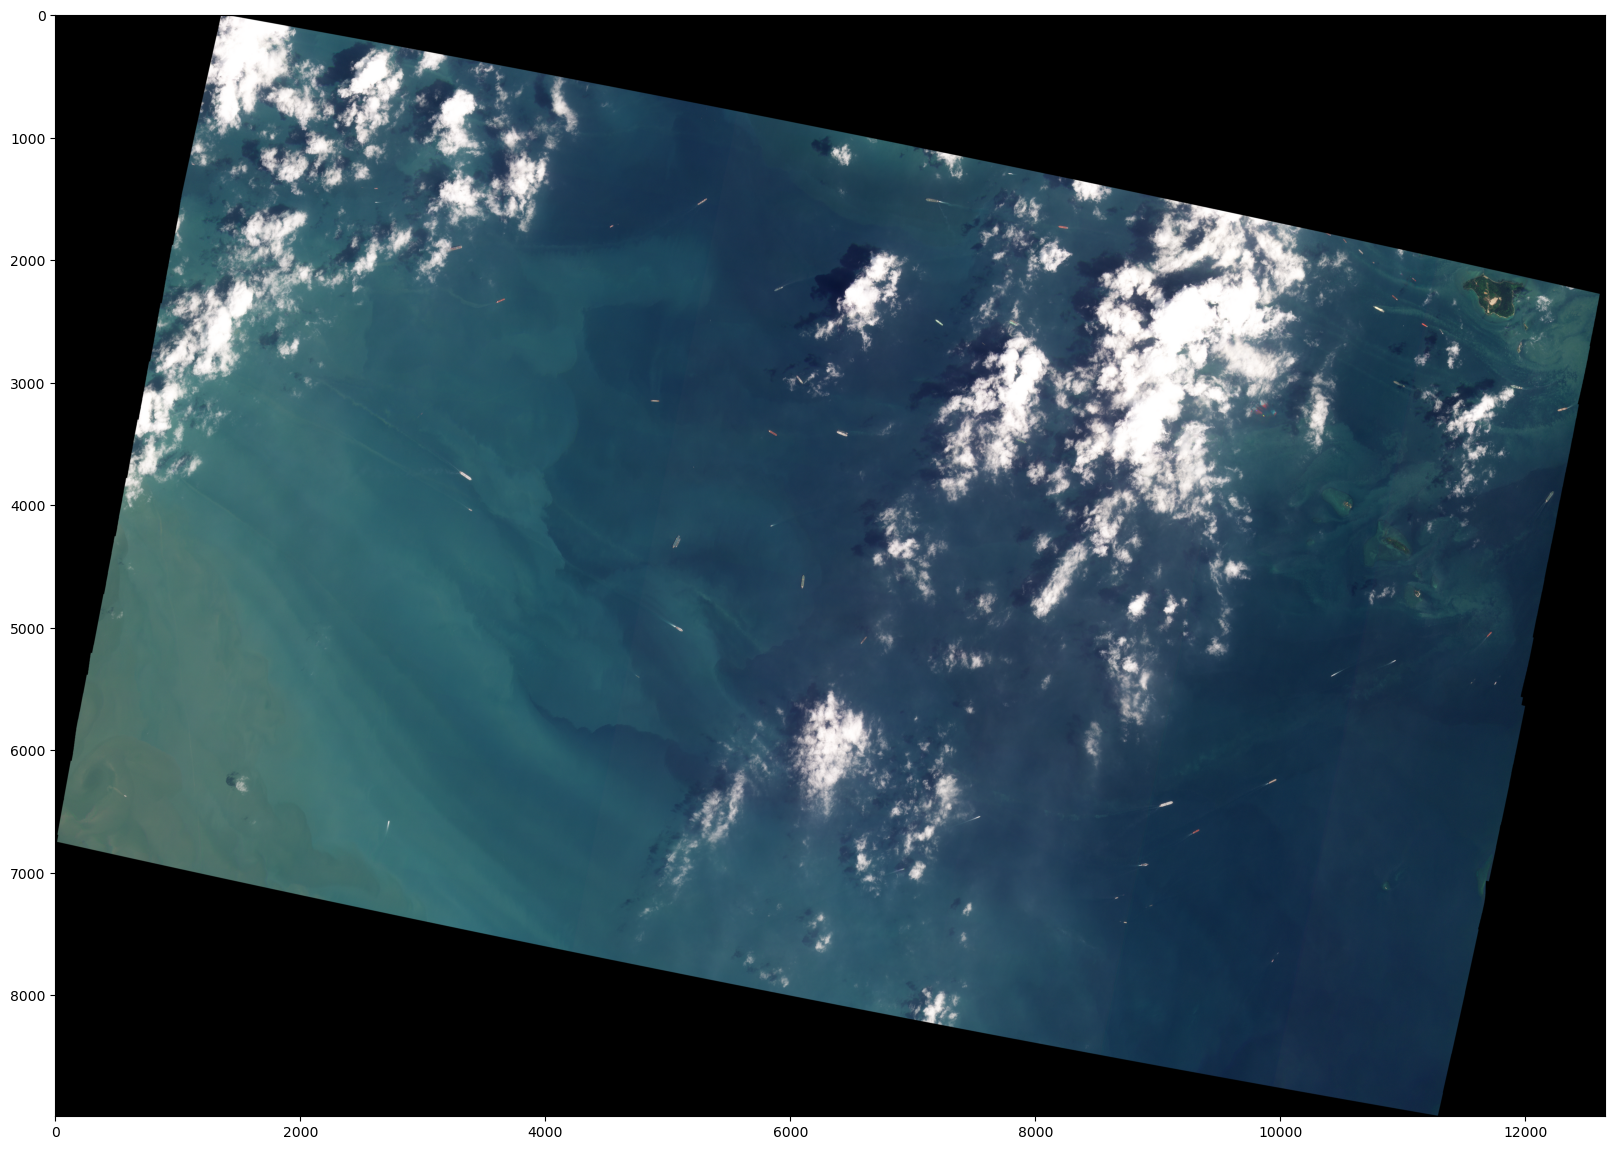

In [9]:
sample_visual_image=tifffile.imread("../data/band_test/visual/20230218_030554_61_24a3_3B_Visual_clip.tif")
plt.figure(figsize=(20,20))
plt.imshow(sample_visual_image[:,:,:3])

In [ ]:
plt.imsave("../results/sample_image.png", transformed_image.astype(np.uint8))